In [2]:
import tensorflow as tf
from keras.preprocessing import image_dataset_from_directory
from sklearn.model_selection import train_test_split
import os
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
from keras import layers, models
import random

# Data Preprocessing

In [12]:
IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224

batch_size = 32
img_size = (IMAGE_HEIGHT, IMAGE_WIDTH) 

data_dir = "../data/Training Data/pngs"
batch_size = 32
img_size = (IMAGE_HEIGHT, IMAGE_WIDTH) 

## Load the full dataset without splitting ##
full_ds = image_dataset_from_directory(
    data_dir,
    image_size=img_size,
    batch_size=1, 
    label_mode='int',
    shuffle=False
)

## create arrays of paths and labels and find limiting class size ##
image_paths = []
labels = []

for image, label in full_ds:
    image_paths.append(image.numpy()[0])  # Get the single image path
    labels.append(label.numpy()[0])  # Get the single label


labels = np.array(labels)
class_counts = defaultdict(int)
for label in labels:
    class_counts[label] += 1

max_samples_per_class = min(class_counts.values())

## Balance the dataset ##
balanced_image_paths = []
balanced_labels = []

class_sample_counts = defaultdict(int)

for image, label in zip(image_paths, labels):
    if class_sample_counts[label] < max_samples_per_class:
        balanced_image_paths.append(image)
        balanced_labels.append(label)
        class_sample_counts[label] += 1

## Split into train and test ##
train_images, val_images, train_labels, val_labels = train_test_split(
    balanced_image_paths, balanced_labels, test_size=0.2, stratify=balanced_labels, random_state=123
)

## Create TensorFlow datasets from the splits ##
def create_dataset(image_paths, labels, batch_size):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    dataset = dataset.map(lambda x, y: (tf.image.resize(x, img_size), y))  # Resize images
    dataset = dataset.batch(batch_size)
    return dataset

train_ds = create_dataset(train_images, train_labels, batch_size)
val_ds = create_dataset(val_images, val_labels, batch_size)

## Normalize images (scale pixel values to [0, 1]) ##
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

## Cache and optimize performance ##
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Class distributions after balancing:")
train_class_counts = defaultdict(int)
val_class_counts = defaultdict(int)

for _, labels in train_ds:
    for label in labels.numpy():
        train_class_counts[label] += 1

for _, labels in val_ds:
    for label in labels.numpy():
        val_class_counts[label] += 1

print(f"Training set: {dict(train_class_counts)}")
print(f"Validation set: {dict(val_class_counts)}")

Found 315 files belonging to 8 classes.
Class distributions after balancing:
Training set: {np.int32(2): 25, np.int32(3): 25, np.int32(1): 25, np.int32(5): 24, np.int32(0): 25, np.int32(4): 25, np.int32(7): 25, np.int32(6): 24}
Validation set: {np.int32(1): 6, np.int32(0): 6, np.int32(4): 6, np.int32(6): 7, np.int32(5): 7, np.int32(7): 6, np.int32(3): 6, np.int32(2): 6}


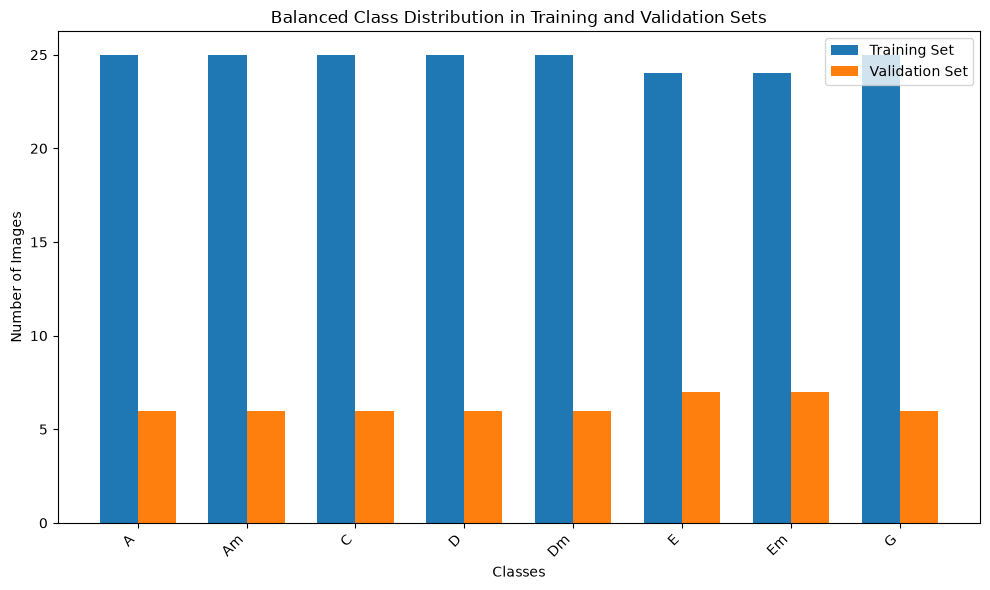

In [13]:
class_names = sorted(os.listdir(data_dir))
class_names = [name for name in class_names if os.path.isdir(os.path.join(data_dir, name))]  # Filter out non-directory files

# Convert class counts to lists
train_counts = [train_class_counts[class_label] for class_label in sorted(train_class_counts.keys())]
val_counts = [val_class_counts[class_label] for class_label in sorted(val_class_counts.keys())]

# plotting stuff
x = np.arange(len(class_names))  
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.35
bar1 = ax.bar(x - bar_width/2, train_counts, bar_width, label='Training Set')
bar2 = ax.bar(x + bar_width/2, val_counts, bar_width, label='Validation Set')
ax.set_xlabel('Classes')
ax.set_ylabel('Number of Images')
ax.set_title('Balanced Class Distribution in Training and Validation Sets')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
def build_cnn(input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3), num_classes=20):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),  # Regularization to prevent overfitting
        layers.Dense(num_classes, activation='softmax')  # Output layer
    ])
    return model

num_classes = 20 
model = build_cnn(input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3), num_classes=num_classes)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/opt/anaconda3/envs/chords/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,171,540 (42.62 MB)

 Trainable params: 11,171,540 (42.62 MB)

 Non-trainable params: 0 (0.00 B)

# Training The Model

In [17]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    mode = 'min',
    patience=4,
    restore_best_weights=True,
    verbose =1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 332ms/step - accuracy: 0.5455 - loss: 1.3106 - val_accuracy: 0.4800 - val_loss: 1.6265
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 314ms/step - accuracy: 0.6010 - loss: 1.2624 - val_accuracy: 0.4800 - val_loss: 1.4957
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 322ms/step - accuracy: 0.5758 - loss: 1.2613 - val_accuracy: 0.4600 - val_loss: 1.5008
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 313ms/step - accuracy: 0.5354 - loss: 1.1900 - val_accuracy: 0.4400 - val_loss: 1.4492
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 323ms/step - accuracy: 0.5960 - loss: 1.0785 - val_accuracy: 0.5400 - val_loss: 1.4125
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 310ms/step - accuracy: 0.6364 - loss: 1.0539 - val_accuracy: 0.5400 - val_loss: 1.4834
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 314ms/step - accuracy: 0.6616 - loss: 0.8253 - val_accuracy: 0.5000 - val_loss: 1.4846
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 313ms/step - accuracy: 0.6061 - loss: 0.9754 - val_accuracy: 0.4400 - val_loss:

# Evaluating Model

In [18]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {val_acc:.2f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5800 - loss: 1.2816
Validation Accuracy: 0.58


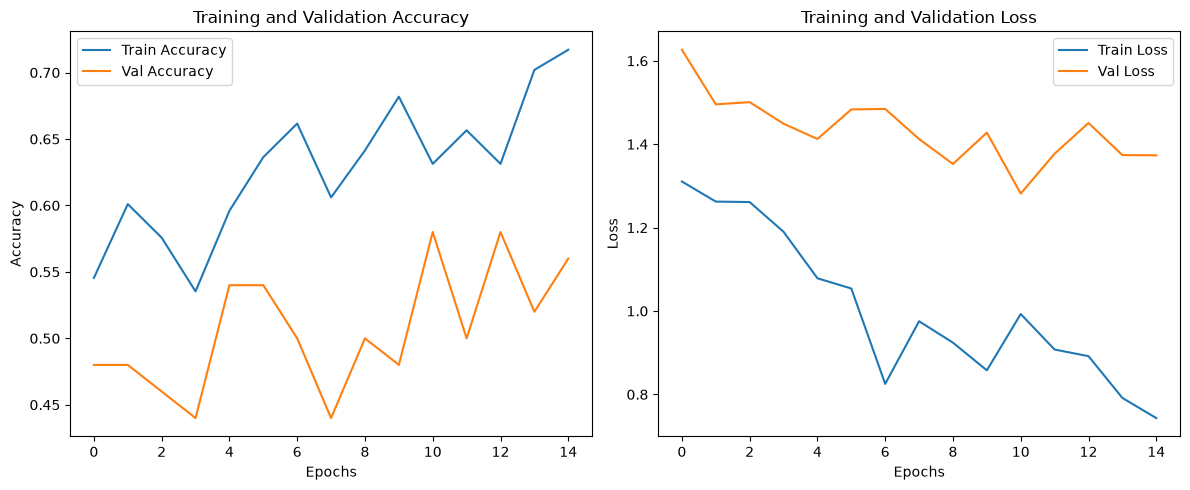

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].legend()
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Training and Validation Accuracy')

# loss
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].legend()
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].set_title('Training and Validation Loss')

plt.tight_layout()
plt.show()